# COMP6010 Practical 02 — Bayesian Updating

**Work time:** 40 minutes  
**Discussion:** 20 minutes  
**Mini-project:** Build a rare-fault diagnostic calculator and study the base-rate effect  
**Software:** NumPy, pandas, matplotlib

## Learning objectives
- construct a binary joint probability table from a prior and likelihoods
- implement Bayes' rule as a reusable function
- perform sequential updating and interpret the base-rate effect

## Suggested timing
- **0–5 min:** answer the five review questions individually.
- **5–10 min:** run the setup and inspect the scenario/data.
- **10–35 min:** complete the implementation and experiment.
- **35–40 min:** record one result and one limitation.
- **40–60 min:** compare approaches and discuss the supplied prompts.

## Five key review questions

**Q1. Name the four quantities in Bayes' rule P(H|E)=P(E|H)P(H)/P(E).**

> Your answer:  

$P(H|E)$ — Posterior Probability: The updated probability of the hypothesis $H$ after observing evidence $E$.

$P(E|H)$ — Likelihood: The probability of observing evidence $E$ given that hypothesis $H$ is true.

$P(H)$ — Prior Probability: The initial probability of hypothesis $H$ before observing evidence.

$P(E)$ — Marginal Likelihood / Evidence: The total probability of observing evidence $E$ under all hypotheses.

**Q2. Why can a highly accurate detector still have a modest posterior probability after a positive result?**

> Your answer: 

Because when the base rate (prior $P(H)$) of a condition is very low, the sheer volume of false positives from the large negative population can dwarf or rival the true positives from the small positive population. This is known as the base-rate fallacy (or base-rate effect).

**Q3. How is the denominator P(E) obtained for a binary hypothesis?**

> Your answer:  

Using the Law of Total Probability: $$P(E) = P(E|H)P(H) + P(E|\neg H)P(\neg H)$$ where $P(\neg H) = 1 - P(H)$.

**Q4. What changes in sequential Bayesian updating after one observation?**

> Your answer:  

The posterior probability computed from the first observation becomes the new prior probability for evaluating subsequent evidence.

**Q5. What assumption is made when two sensor readings are treated as conditionally independent given the hypothesis?**

> Your answer:

It assumes that given the true state $H$, the error or occurrence of the second sensor reading provides no extra information about the first reading, i.e., $P(E_1, E_2 | H) = P(E_1|H) \cdot P(E_2|H)$.

## Scenario
A factory component has a hidden fault state. A monitoring alarm is sensitive but not perfect.

- P(Fault) = 0.03
- P(Alarm | Fault) = 0.92
- P(Alarm | No fault) = 0.08

Estimate P(Fault | Alarm), then explore how it changes with the fault base rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 6010
rng = np.random.default_rng(RANDOM_SEED)
np.set_printoptions(precision=4, suppress=True)

### Task 1 — Construct the joint probability table

In [2]:
prior = 0.03
sensitivity = 0.92
false_positive_rate = 0.08

# TODO solution:
joint = pd.DataFrame(
    [
        [prior * sensitivity, prior * (1 - sensitivity)],
        [
            (1 - prior) * false_positive_rate,
            (1 - prior) * (1 - false_positive_rate),
        ],
    ],
    index=["Fault", "No Fault"],
    columns=["Alarm", "No Alarm"],
)

print(joint)

           Alarm  No Alarm
Fault     0.0276    0.0024
No Fault  0.0776    0.8924


### Task 2 — Implement Bayes' rule
Complete a function that returns P(Fault | Alarm). Use total probability for the denominator.

In [3]:
def bayes_positive(prior, sensitivity, false_positive_rate):
  # Calculate total probability of an alarm P(Alarm)
  p_alarm = (sensitivity * prior) + (false_positive_rate * (1 - prior))
  # Return posterior P(Fault | Alarm)
  return (sensitivity * prior) / p_alarm


posterior = bayes_positive(prior, sensitivity, false_positive_rate)
print(f"Posterior P(Fault|Alarm): {posterior:.4f}")  # Output: 0.2624

Posterior P(Fault|Alarm): 0.2624


### Task 3 — Base-rate experiment
Plot the posterior after a positive alarm for priors from 0.1% to 30%. Mark the original prior of 3%.

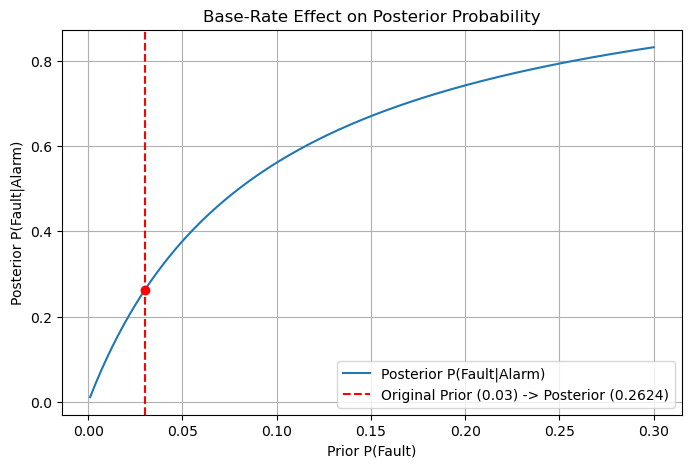

In [4]:
priors = np.linspace(0.001, 0.30, 300)
posteriors = bayes_positive(priors, sensitivity, false_positive_rate)

plt.figure(figsize=(8, 5))
plt.plot(priors, posteriors, label="Posterior P(Fault|Alarm)")
plt.axvline(
    x=0.03,
    color="r",
    linestyle="--",
    label=f"Original Prior (0.03) -> Posterior ({posterior:.4f})",
)
plt.scatter([0.03], [posterior], color="r", zorder=5)
plt.xlabel("Prior P(Fault)")
plt.ylabel("Posterior P(Fault|Alarm)")
plt.title("Base-Rate Effect on Posterior Probability")
plt.legend()
plt.grid(True)
plt.show()

### Task 4 — Sequential evidence
Assuming two alarm readings are conditionally independent given the fault state, update once and then use that posterior as the prior for a second positive alarm.

In [5]:
posterior_after_one = bayes_positive(prior, sensitivity, false_positive_rate)
posterior_after_two = bayes_positive(
    posterior_after_one, sensitivity, false_positive_rate
)

print(f"Posterior after 1 alarm: {posterior_after_one:.4f}")  # Output: 0.2624
print(f"Posterior after 2 alarms: {posterior_after_two:.4f}")  # Output: 0.8035

Posterior after 1 alarm: 0.2624
Posterior after 2 alarms: 0.8035


### Task 5 — Decision interpretation
Suppose inspection costs $50, missing a true fault costs $2,000, and inspection perfectly reveals the state. Is a posterior probability alone enough to decide? Write the additional expected-cost calculation that would be needed.

No. Probability alone tells us the likelihood of a state, but optimal decision-making
requires evaluating expected costs/risks.

Expected Cost Calculation: Let p = P(Fault | Alarm).

Expected Cost(Inspect) = 50 (fixed cost of inspection).

Expected Cost(Do Not Inspect) = 2000 p dollars.

Decision Rule: Inspect if 50 < 2000 p, i.e. p > 0.025.

Since p = 0.2624, inspection is economically justified.

## Discussion — 20 minutes
1. Why is P(Alarm|Fault) not the same quantity as P(Fault|Alarm)?

Answer:
* $P(\text{Alarm}|\text{Fault})$ is sensor sensitivity (how reliably the alarm fires when a fault exists).
* $P(\text{Fault}|\text{Alarm})$ is diagnostic confidence (how likely a fault is when an alarm fires).
* Conflating the two is known as the transposed conditional fallacy. $P(\text{Fault}|\text{Alarm})$ heavily depends on the base rate $P(\text{Fault})$, whereas sensitivity is an intrinsic property of the alarm sensor.

2. How would correlated sensor errors change the two-positive calculation?

Answer:
* If sensor errors are positively correlated (e.g., environmental interference causes both readings to false-alarm together), the second reading provides less independent evidence.
* Mathematically, $P(\text{Alarm}_2 | \text{Alarm}_1, \text{No Fault}) > P(\text{Alarm}_2 | \text{No Fault})$.
* Therefore, assuming independence overestimates confidence; with correlated errors, the true posterior after two alarms would be lower than $80.35%$.

3. At what posterior would inspection be worthwhile under the stated costs?
* Inspection is worthwhile whenever the posterior probability of a fault is $\ge 2.5%$ ($\frac{\$50}{\$2000}$).

## Evidence to retain for a practical portfolio
- the 2×2 joint table
- the reusable Bayes function and base-rate plot
- the sequential-update result and decision explanation